# Regression models with scikit-learn

## Motivation

- OLS: coefficients chosen to minimize the sum of squared errors
  $$
  L(\mu, \bm{\beta}) =
  \sum_{i=1}^N (y_i - \mu - \mathbf{x}_i'\bm{\beta})^2
  $$
- Best linear unbiased estimator (BLUE) under the Gauss-Markov assumptions
- Possible problems:
  - Overfitting with many correlated features
  - Poor prediction accuracy on new observations
- **Solution:**
  - **Regularization:** add penalties for large coefficients to limit overfitting
  - Ridge: L2 regularization
  - Lasso: L1 regularization
  - Elastic Net: combination of L1 and L2 regularization

***
## Synthetic sample and polynomial approximation

### Synthetic sample

- True relationship:
    $$
    y_i = \cos\left(\frac{3\pi}{200} x_i\right) + \epsilon_i
    $$
- $x_i \sim \text{Uniform}[0,100]$
- $\epsilon_i \sim \mathcal{N}(0,0.5^2)$
- Training sample: $N=100$, seed `12345`

In [1]:
import numpy as np


def compute_true_y(x):
    """
    True trigonometric function (without errors)
    """
    return np.cos(3 * np.pi / 200.0 * x)

In [2]:
from numpy.random import default_rng


def create_trig_sample(N=100, sigma=0.5, rng=None):
    """
    Create trigonometric relationship sample data.

    Parameters
    ----------
    N : int
        Sample size.
    sigma : float
        Standard deviation of the normal error term.
    rng : np.random.Generator, optional
        Random number generator.
    """

    # Initialize random number generator
    if rng is None:
        rng = default_rng(seed=12345)

    # Randomly draw explanatory variable x uniformly distributed on [0, 100]
    x = rng.uniform(0, 100, size=N)

    # Draw errors from normal distribution
    epsilon = rng.normal(scale=sigma, size=N)

    # Compute y, add measurement error
    y = compute_true_y(x) + epsilon

    return x, y

### Shared training sample and prediction grid

- Same training observations for OLS, Ridge, Lasso, and Elastic Net
- Feature matrix: one column, one row per observation

In [6]:
# Polynomial degree used throughout the notebook
DEGREE = 15

# TODO: Generate the training sample with create_trig_sample()
x_train, y_train = create_trig_sample()

# TODO: Convert x_train to a two-dimensional feature matrix
X_train = x_train[:, None]

In [7]:
# Common grid for prediction plots within the training range
xvalues = np.linspace(x_train.min(), x_train.max(), 500)

# Matrix of features used for predict()
X_grid = xvalues[:, None]

### Sample and true function

- Baseline plot with `plot_trig_sample()`

In [8]:
def plot_trig_sample(x, y):
    """
    Plot the trigonometric relationship and sample.
    """
    import matplotlib.pyplot as plt

    # Sample scatter plot
    _, ax = plt.subplots(figsize=(5.5, 3.5), layout='constrained')
    ax.scatter(x, y, s=20, c='none', edgecolor='steelblue', lw=0.75, label='Sample')

    # Plot true relationship
    x_true = np.linspace(0.0, 100.0, 101)
    y_true = compute_true_y(x_true)
    ax.plot(x_true, y_true, c='black', lw=1.0, label='True function')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.legend(loc='upper right')

    return ax

<Axes: xlabel='$x$', ylabel='$y$'>

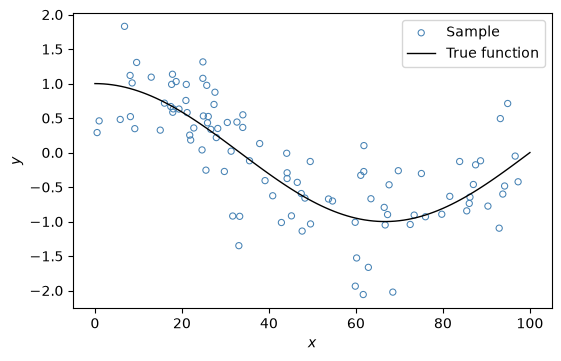

In [9]:
# TODO: Plot the training sample and true function
plot_trig_sample(x_train, y_train)

***
### Polynomial approximation

- Pretend we don't know the true relationship
- Polynomial approximation of degree $K=15$:
  $$
  y_i \approx \mu + \beta_1 x_i + \beta_2 x_i^2 + \cdots + \beta_K x_i^K
  $$
- Four pipeline steps with
  [`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html):

  1. Input centering and scaling with
     [`StandardScaler()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
     - Manageable powers and a different polynomial basis
  2. Degree-15 powers with
     [`PolynomialFeatures()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
     - `include_bias=False`: intercept in the regression step
  3. Standardization of expanded columns with `StandardScaler()`
     - Comparable feature scales
  4. Regression model fitted to the transformed features

### OLS benchmark

- Four-step pipeline defined above
- Estimation with
  [`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# TODO: Build the four-step pipeline with LinearRegression as the final step
pipe_ols = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    LinearRegression(fit_intercept=True)
)

# TODO: Fit pipe_ols on X_train and y_train
pipe_ols.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


### OLS predictions

- Predictions on `X_grid` with
  [`predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.predict)
- Sample, true function, and OLS fitted curve

In [12]:
# TODO: Predict OLS values on X_grid
yhat_grid_ols = pipe_ols.predict(X_grid)

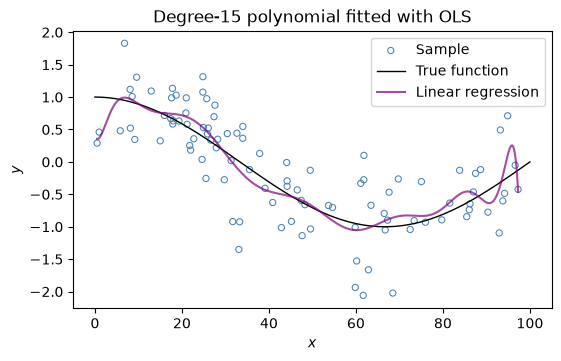

In [14]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# OLS prediction
ax.plot(xvalues, yhat_grid_ols, c='purple', alpha=0.7, label='Linear regression')

ax.set_title(f'Degree-{DEGREE} polynomial fitted with OLS')
_ = ax.legend()

- Scaling: equivalent polynomial in exact arithmetic
- Numerical stability and overfitting: separate issues
- OLS predictions can follow sample noise even with stable calculations

***
## Ridge regression

- Sum of squared errors plus an **L2 penalty**:
  $$
  L(\mu, \bm{\beta}) =
  \sum_{i=1}^N (y_i - \mu - \mathbf{x}_i'\bm{\beta})^2
  + \alpha \sum_{k=1}^K \beta_k^2
  $$
- Larger $\alpha$: more shrinkage overall
- Intercept unpenalized
- Small $\alpha$: approaches OLS

#### Importance of scaling and centering

- Second scaler: comparable feature scales for the coefficient penalty
- Centering changes polynomial coefficients and therefore what the penalty shrinks
- Input standardization can improve numerical stability; prediction accuracy need not
  improve

### Estimating the Ridge model

- Same preprocessing as the OLS pipeline
- Final step with
  [`Ridge()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
- Illustrative regularization strength: $\alpha=3$

In [15]:
from sklearn.linear_model import Ridge

alpha = 3

# TODO: Build the four-step Ridge pipeline with degree DEGREE and penalty alpha
pipe_ridge = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias= False),
    StandardScaler(),
    Ridge(alpha=alpha, fit_intercept=True)
)

# TODO: Fit pipe_ridge on X_train and y_train
pipe_ridge.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


### Comparing predictions

- Predictions on `X_grid` with
  [`predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.predict)
- Sample, true function, and both fitted curves

In [16]:
# TODO: Predict illustrative Ridge values on X_grid
yhat_grid_ridge = pipe_ridge.predict(X_grid)

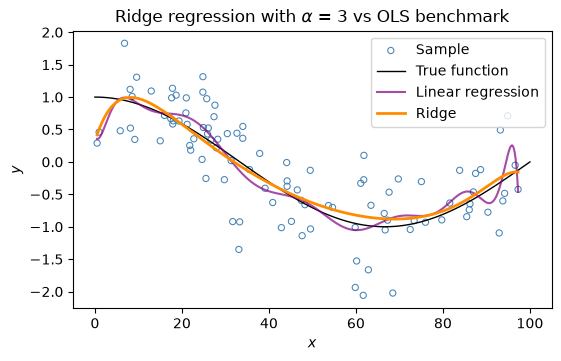

In [17]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Linear regression prediction
ax.plot(xvalues, yhat_grid_ols, c='purple', alpha=0.7, label='Linear regression')

# Ridge prediction
ax.plot(xvalues, yhat_grid_ridge, c='darkorange', lw=2.0, label='Ridge')

ax.set_title(rf'Ridge regression with $\alpha$ = {alpha:.4g} vs OLS benchmark')
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Comment out the first `StandardScaler()` in the Ridge and OLS pipelines above.
   Rerun the fits, predictions, and graph.
2. Restore the first scaler, then comment out the `StandardScaler()` after
   `PolynomialFeatures`. Rerun and inspect the graph again.

How does removing each scaler affect the Ridge predictions relative to OLS?
Why does feature scaling matter when we penalize coefficients?

Restore both scaling steps before continuing.

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Ridge path

- Plots coefficients over a range of penalties
  - Here: Grid of 200 penalties on $[10^{-4},100]$
  - Logarithmic grid with
    [`np.logspace()`](https://numpy.org/doc/stable/reference/generated/numpy.logspace.html)
- Pipeline parameter updates with
  [`set_params()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.set_params)
  - `ridge__alpha`: step name and parameter separated by two underscores
- Fitted coefficients: `named_steps['ridge'].coef_`

In [19]:
# TODO: Create 200 logarithmically spaced penalties from 1e-4 to 100
alphas = np.logspace(np.log10(1e-4), np.log10(100),200)

# TODO: Allocate a coefficient array with shape (len(alphas), DEGREE)
coefs = np.empty((len(alphas), DEGREE))

# TODO: Loop over alphas with enumerate()
for i, alpha in enumerate(alphas):
    pipe_ridge.set_params(ridge__alpha=alpha)
    pipe_ridge.fit(X_train, y_train)
    coefs[i] = pipe_ridge.named_steps['ridge'].coef_

# TODO: Update ridge__alpha, refit the pipeline, and store coefficients in coefs[i]

In [22]:
def plot_coefficient_path(alphas, coefs, model_name):
    """
    Plot coefficients for different regularization strengths.

    Parameters
    ----------
    alphas : array
        Regularization strengths
    coefs : array
        Coefficients, with one row per strength and one column per feature
    model_name : str
        Model name, either 'Ridge' or 'Lasso'
    """
    import matplotlib.pyplot as plt

    _, ax = plt.subplots(figsize=(6, 4), layout='constrained')
    colors = plt.get_cmap('tab20').colors

    # Use a separate color for each standardized polynomial feature
    for i in range(coefs.shape[1]):
        ax.plot(alphas, coefs[:, i], lw=1.0, c=colors[i], label=rf'$\beta_{{{i + 1}}}$')

    ax.set_xscale('log', base=10)
    ax.axhline(0.0, ls='--', lw=0.75, c='black')
    ax.set_xlabel(r'Regularization strength $\alpha$ (log scale)')
    ax.set_ylabel('Coefficient on standardized feature')
    title = f'{model_name} coefficients as a function of regularization strength'
    ax.set_title(title)
    _ = ax.legend(ncols=5)

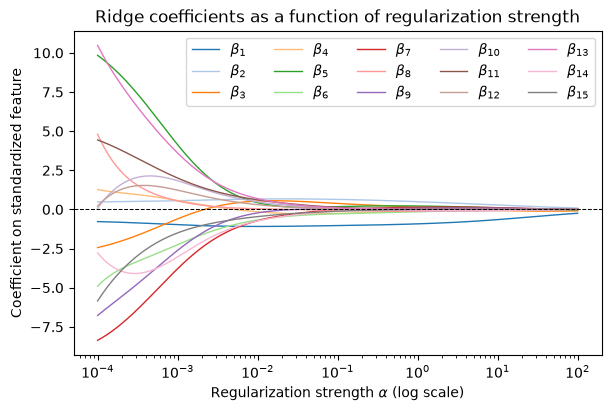

In [23]:
# TODO: Plot the Ridge coefficient path with plot_coefficient_path()
plot_coefficient_path(alphas, coefs, 'Ridge', )

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Find the largest absolute coefficient in the fitted OLS model `pipe_ols`.
   
   *Hint:* The OLS coefficients are stored in the attribute `coef_` in the `'linearregression'` step of the pipeline.

2. Find the largest absolute Ridge coefficient at the left endpoint of the
   path, where the penalty is $\alpha = 10^{-4}$. These coefficients are stored in
   `coefs[0]`.
3. Compare the two values. Does the smallest penalty in our path give
   coefficients close to OLS? What does this tell us about the shrinkage
   produced by a small positive penalty?


</div>
<span style="display: none;">YourTurnEnd</span>

***
### Selecting Ridge regularization by cross-validation

- Use
  [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
  - Pass complete Ridge pipeline
  - Scalers fitted separately within each training fold
  - Parameter grid: 200 candidate penalties on $[10^{-4},100]$
- Five shared shuffled folds with
  [`KFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)
  - `random_state=1234`
- `scoring='neg_mean_squared_error'`
  - Larger score: smaller MSE

In [25]:
from sklearn.model_selection import GridSearchCV, KFold

# TODO: Create five shuffled folds with random_state=1234
cv = KFold(n_splits=5, shuffle=True, random_state=1234)

# TODO: Set the negative MSE scoring rule
scoring = 'neg_mean_squared_error'

# TODO: Create 200 logarithmically spaced Ridge penalties from 1e-4 to 100
ridge_alphas = np.logspace(np.log10(1e-4), np.log10(100), 200)

# TODO: Recreate the four-step pipeline with Ridge() as the final step
pipe_ridge = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    Ridge()
)

In [28]:
# TODO: Create GridSearchCV for ridge__alpha using ridge_alphas, scoring, and cv
# TODO: Enable refit=True and n_jobs=4
ridge_cv = GridSearchCV(
    pipe_ridge,
    param_grid={'ridge__alpha':ridge_alphas},
    cv=cv,
    scoring=scoring,
    n_jobs=4,
    refit=True
)

# TODO: Fit ridge_cv on X_train and y_train
ridge_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

Useful attributes of the fitted `GridSearchCV` object:

- `best_params_`: selected hyperparameters
- `best_score_`: mean validation score at the selected hyperparameters
    - CV MSE: negative of `best_score_`

In [33]:
# TODO: Extract the selected ridge__alpha from best_params_
alpha_best = ridge_cv.best_params_['ridge__alpha']
print(f'Best alpha for Ridge: {alpha_best}')

# TODO: Convert best_score_ to positive MSE
mse_ridge_cv = - ridge_cv.best_score_
print(f'Best CV MSE for Ridge: {mse_ridge_cv:.4g}')

# TODO: Print the selected alpha and CV MSE

Best alpha for Ridge: 1.350993521198025
Best CV MSE for Ridge: 0.2489


***
### Ridge validation curve

Fitted `GridSearchCV` object provides data to plot validation curve:

- `cv_results_`: candidate penalties and mean validation scores


In [34]:
def plot_validation_curve(search, model_name):
    """
    Plot validation MSE against alpha and mark the selected value.

    Parameters
    ----------
    search : object
        Fitted GridSearchCV search over the model's alpha
    model_name : str
        Model name, either 'Ridge' or 'Lasso'
    """
    import matplotlib.pyplot as plt

    # Recover candidate alphas, mean validation errors, and the selected index
    param_name = f'param_{model_name.lower()}__alpha'
    alphas = search.cv_results_[param_name]
    mse_mean = -search.cv_results_['mean_test_score']
    imin = search.best_index_

    # Plot the validation curve and highlight the selected alpha
    _, ax = plt.subplots(figsize=(5, 3), layout='constrained')
    ax.plot(alphas, mse_mean)
    ax.scatter(alphas[imin], mse_mean[imin], s=15, c='black', zorder=100)
    ax.axvline(alphas[imin], ls=':', lw=0.75, c='black')
    ax.set_xscale('log')
    ax.set_xlabel(r'Regularization strength $\alpha$ (log scale)')
    ax.set_ylabel('Cross-validated MSE')
    _ = ax.set_title(f'Validation curve for {model_name}')

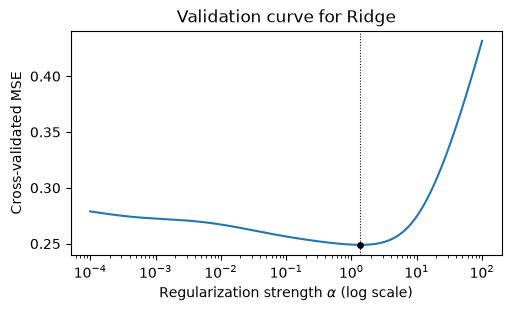

In [35]:
# TODO: Plot the Ridge validation curve with plot_validation_curve()
plot_validation_curve(ridge_cv, 'Ridge')

### Predictions from the selected Ridge model

Fitted `GridSearchCV` object provides the selected Ridge model:

- `best_estimator_`: selected pipeline refitted on all training observations

In [36]:
# TODO: Recover the fitted best_estimator_ from ridge_cv
pipe_ridge = ridge_cv.best_estimator_

# TODO: Predict on X_grid with the selected Ridge model
yhat_grid_ridge = pipe_ridge.predict(X_grid)

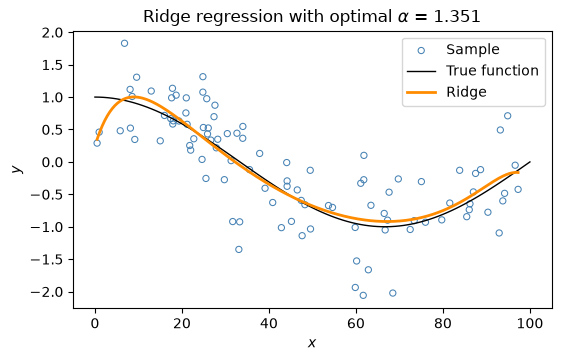

In [37]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot predicted values from cross-validated Ridge regression
ax.plot(xvalues, yhat_grid_ridge, c='darkorange', lw=2.0, label='Ridge')

ax.set_title(rf'Ridge regression with optimal $\alpha$ = {alpha_best:.4g}')
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Repeat the OLS and Ridge analysis with `N=200`. How do the predictions change?
2. What happens to the selected $\alpha$? Also compare
    $\alpha/N$: dividing Ridge's objective by $N$ gives mean squared error plus a penalty
    with weight $\alpha/N$. This helps us compare penalty strengths across sample sizes.

Restore `N=100` and rerun the analysis before continuing.

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Dedicated Ridge cross-validation

- Built-in cross-validation with
  [`RidgeCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html)
  - Default `cv=None`: efficient leave-one-out calculation
  - Fitting scalers on the full sample before internal CV causes data leakage

**Alternative transformation:**

- Fixed features: powers of $z=(x-50)/100$, without learned scalers
- No sample means or scales estimated before CV
- Different basis and scales: selected penalty not directly comparable

In [ ]:
from sklearn.linear_model import RidgeCV

# Fixed feature construction; no scales are estimated from the sample
poly = PolynomialFeatures(degree=DEGREE, include_bias=False)
X_train_fixed = poly.fit_transform((X_train - 50) / 100)

# Candidate strengths for these fixed feature scales
ridge_alphas_dedicated = np.logspace(-5, 2, num=200)

# TODO: Create RidgeCV with ridge_alphas_dedicated
# ridge_cv_dedicated =

# TODO: Fit on X_train_fixed and y_train
# TODO: Print the selected alpha_

***
## Lasso

- Adds L1 penalty:
  $$
  L(\mu, \bm{\beta}) =
  \frac{1}{2N}\sum_{i=1}^N (y_i-\mu-\mathbf{x}_i'\bm{\beta})^2
  + \alpha \sum_{k=1}^K |\beta_k|
  $$
- Intercept unpenalized
- Exactly zero coefficients possible: feature selection
- Different loss scaling and penalty from Ridge

### Estimating Lasso

- Same training sample and two scaling steps
- Estimation with
  [`Lasso`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)
  - Illustrative penalty: $\alpha=0.0075$
  - `max_iter=10_000`, `tol=1e-6` for correlated polynomial features

In [38]:
from sklearn.linear_model import Lasso

alpha = 0.0075

# TODO: Build the four-step Lasso pipeline with alpha, max_iter=10_000, tol=1e-6
pipe_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    Lasso(alpha=alpha)
)

# TODO: Fit pipe_lasso on X_train and y_train
pipe_lasso.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


In [39]:
# TODO: Predict illustrative Lasso values on X_grid
yhat_grid_lasso = pipe_lasso.predict(X_grid)

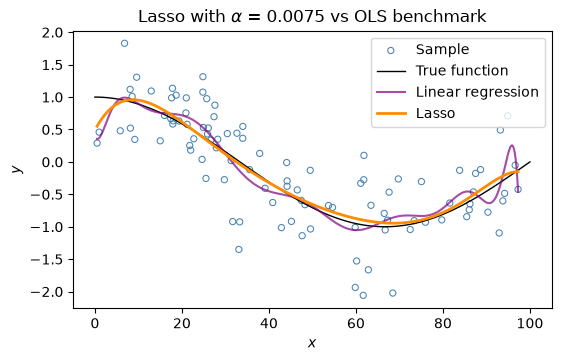

In [40]:
ax = plot_trig_sample(x_train, y_train)

# Linear regression prediction
ax.plot(xvalues, yhat_grid_ols, c='purple', alpha=0.7, label='Linear regression')

# Lasso prediction
ax.plot(xvalues, yhat_grid_lasso, c='darkorange', lw=2.0, label='Lasso')

ax.set_title(rf'Lasso with $\alpha$ = {alpha:.4g} vs OLS benchmark')
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Set `alpha=1` in the Lasso setup and rerun the fit and prediction plot. How does the
fitted curve change? Explain the intuition behind this result.

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Lasso path

- Plots Lasso coefficients over a range of penalties
    - 200 penalties on $[10^{-4},1]$
- May need to increase `max_iter` for convergence
    - `max_iter=20_000_000`
- `precompute=True` to speed up the fit

In [46]:
# Create grid of alphas spaced uniformly in logs on [1e-4, 1]
alphas = np.logspace(start=np.log10(1.0e-4), stop=np.log10(1.0), num=200)

# TODO: Create pipeline with larger max_iter and precompute=True
pipe_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    Lasso(alpha=alpha, max_iter=1_000_000, precompute=True)
)

# Array to store one coefficient for each polynomial feature and alpha
coefs = np.empty((len(alphas), DEGREE))

# TODO: Loop over alphas
for i, alpha in enumerate(alphas):
    pipe_lasso.set_params(lasso__alpha= alpha)

    pipe_lasso.fit(X_train, y_train)

    coefs[i]= pipe_lasso.named_steps['lasso'].coef_
# TODO: Update lasso__alpha, refit, and store coefficients in coefs[i]

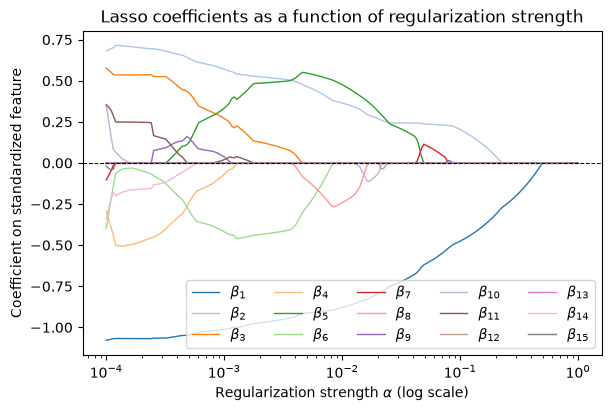

In [47]:
# TODO: Plot the Lasso coefficient path with plot_coefficient_path()
plot_coefficient_path(alphas, coefs, 'Lasso')

### Counting retained features


In [48]:
# TODO: Count coefficients above 1e-6 in absolute value for each row of coefs
nonzero = np.sum(np.abs(coefs)> 1e-6, axis = 1)

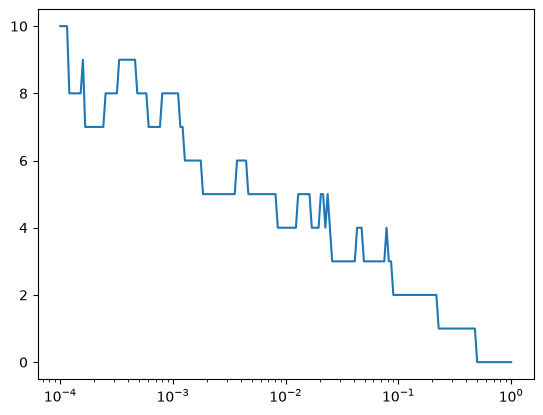

In [50]:
import matplotlib.pyplot as plt

# TODO: Plot nonzero against alphas
# TODO: Use a logarithmic x-axis, integer count ticks, and axis labels

plt.plot(alphas, nonzero)
plt.xscale('log')

***
### Selecting Lasso regularization by cross-validation

- Use `GridSearchCV` around the complete pipeline
  - Scalers fitted separately within each training fold
  - Same folds and scoring rule
  - Parameter grid: 200 penalties on $[10^{-4},10^{-1}]$
- Built-in cross-validation with
  [`LassoCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html)
  can causes data leakage if we require scaling

In [53]:
# TODO: Create 200 logarithmically spaced Lasso penalties from 1e-4 to 1e-1
lasso_alphas = np.logspace(np.log10(1e-4), np.log10(1e-1), 200)

# TODO: Rebuild the Lasso pipeline with the solver settings above
pipe_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False), 
    StandardScaler(),
    Lasso(max_iter=1_000_000, tol=1.0e-6, precompute=True)
)

# TODO: Create GridSearchCV for lasso__alpha with shared scoring and cv
lasso_cv = GridSearchCV(
    pipe_lasso,
    param_grid={'lasso__alpha': lasso_alphas},
    cv=cv,
    scoring=scoring,
    n_jobs=4,
    refit=True,
)

lasso_cv.fit(X_train, y_train)
# TODO: Enable refit=True and n_jobs=4; fit on X_train and y_train

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=1e-06))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lasso__alpha': array([0.0001..., 0.1 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls

In [55]:
# TODO: Extract the selected lasso__alpha from best_params_
alpha_best = lasso_cv.best_params_['lasso__alpha']
print(f'Best Lasso alpha: {alpha_best}')

# TODO: Convert the selected validation score to positive MSE
mse_lasso_cv = - lasso_cv.best_score_
print(f'CV MSE for Lasso: {mse_lasso_cv}')

# TODO: Print the selected alpha and CV MSE

Best Lasso alpha: 0.00505263106533568
CV MSE for Lasso: 0.24873674190344502


- Fitted Lasso step: `best_estimator_.named_steps['lasso']`
- Retained features: absolute coefficient above $10^{-6}$
- Validation curve with `plot_validation_curve()`

In [ ]:
# TODO: Recover the fitted Lasso step from the selected pipeline
# lasso_best =

# TODO: Count nonzero coefficients using the 1e-6 threshold
# n_features =

# TODO: Print the feature count
# TODO: Plot the Lasso validation curve

### Predictions from the selected Lasso model

- Reuse the refitted best pipeline

In [ ]:
# TODO: Recover the fitted best_estimator_ from lasso_cv
# pipe_lasso =

# TODO: Predict on X_grid with the selected Lasso model
# yhat_grid_lasso =

In [ ]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot prediction from optimal Lasso model
ax.plot(xvalues, yhat_grid_lasso, c='darkorange', lw=2.0, label=r'Lasso')

ax.set_title(rf'Lasso with optimal $\alpha$ = {alpha_best:.4g}')
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Perform the following tasks using the fitted Lasso model `pipe_lasso`:

- Compute the training MSE using the predicted values `pipe_lasso.predict(X_train)` and `y_train`.

    *Hint:* You can use
    [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)
    from `sklearn.metrics` to compute the MSE.

- Compare the training MSE with the CV MSE stored in `mse_lasso_cv`. Which is lower
  for this sample? What could explain the difference?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Dedicated Lasso cross-validation

- Built-in cross-validation with
  [`LassoCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html)
  - Previous coefficient solutions reused along the penalty path: warm starts
  - Selected value in `alpha_` attribute

**Alternative transformation:**

- Fixed powers of $z=(x-50)/100$, without learned scalers
- Different basis and scales from the main pipeline

In [ ]:
from sklearn.linear_model import LassoCV

# TODO: Create degree-DEGREE polynomial features without a bias column
# poly =

# TODO: Construct fixed polynomial features from (X_train - 50) / 100
# X_train_fixed =

# TODO: Create 200 logarithmically spaced penalties from 1e-5 to 1e-2
# lasso_alphas_dedicated =

# TODO: Create LassoCV with these penalties, cv=cv, and max_iter=1_000_000
# lasso_cv_dedicated =

# TODO: Fit on X_train_fixed and y_train; print the selected alpha_

***
## Elastic Net

- Combined L1 and L2 penalties:
  $$
  L(\mu,\bm{\beta}) =
  \frac{1}{2N}\sum_{i=1}^N (y_i-\mu-\mathbf{x}_i'\bm{\beta})^2
  + \alpha\rho\sum_{k=1}^K|\beta_k|
  + \frac{\alpha(1-\rho)}{2}\sum_{k=1}^K\beta_k^2
  $$

- $\rho=$ `l1_ratio`: penalty mix
  - $\rho=1$: Lasso
  - $\rho=0$: L2 only, equivalent Ridge strength $\alpha_{\text{Ridge}} = N \cdot \alpha_{\text{Elastic Net}}$
- Intercept unpenalized

### Estimating Elastic Net

- Estimation with
  [`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html)
  - `alpha=0.01`, `l1_ratio=0.5`
  - `max_iter=100_000`, `tol=1e-6`
- Same training sample and preprocessing

In [ ]:
from sklearn.linear_model import ElasticNet

# TODO: Build the four-step Elastic Net pipeline with the settings above
# pipe_enet =

# TODO: Fit pipe_enet on X_train and y_train

In [ ]:
# Grid predictions from the illustrative Elastic Net model
yhat_grid_enet = pipe_enet.predict(X_grid)

# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot predictions
ax.plot(xvalues, yhat_grid_ols, c='purple', lw=1.5, ls='-', label='OLS')
ax.plot(xvalues, yhat_grid_enet, c='darkorange', lw=2.0, label='Elastic Net')

ax.set_title(r'Elastic Net vs. OLS benchmark')
_ = ax.legend()

### Selecting both Elastic Net hyperparameters

- Use `GridSearchCV` to select both `alpha` and `l1_ratio`
    - Alphas: 200 penalties on $[10^{-4},10^{-1}]$
    - L1 ratios: `[0.001, 0.01, 0.1, 0.5, 0.9, 0.95]`
- Parameter names: `elasticnet__alpha`, `elasticnet__l1_ratio`
- Complete pipeline with `max_iter=20_000_000`, `tol=1e-6`, `precompute=True`

In [ ]:
# Candidate values for both hyperparameters
l1_ratios = [0.001, 0.01, 0.1, 0.5, 0.9, 0.95]
enet_alphas = np.logspace(-4, -1, num=200)

# TODO: Rebuild the Elastic Net pipeline with the solver settings above
# pipe_enet =

# TODO: Create the parameter grid for elasticnet__alpha and elasticnet__l1_ratio
# param_grid =

In [ ]:
# TODO: Create GridSearchCV using pipe_enet, param_grid, scoring, and cv
# Enable refit=True and n_jobs=4
# enet_cv =

# TODO: Fit enet_cv on X_train and y_train

In [ ]:
# TODO: Extract the selected elasticnet__alpha
# alpha_best =

# TODO: Extract the selected elasticnet__l1_ratio
# l1_ratio_best =

# TODO: Convert the selected validation score to positive MSE
# mse_enet_cv =

# TODO: Print the selected alpha, L1 ratio, and CV MSE

### Predictions from the selected Elastic Net model

- Reuse the refitted best pipeline

In [ ]:
# TODO: Recover the fitted best_estimator_ from enet_cv
# pipe_enet =

# TODO: Predict on X_grid with the selected Elastic Net model
# yhat_grid_enet =

In [ ]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot prediction from optimal Elastic Net model
ax.plot(xvalues, yhat_grid_enet, c='darkorange', lw=2.0, label='Elastic Net')

title = rf'Elastic Net with $\alpha$={alpha_best:.4g}, $\rho$={l1_ratio_best:.4g}'
ax.set_title(title)
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Using the code from above, perform the following tasks:

- Count the nonzero coefficients in the selected Elastic Net model, using the same
  $10^{-6}$ threshold as for Lasso. How many additional features does Elastic Net retain?
- Compare the CV MSEs of the two models. Is the improvement from Elastic Net substantial?

*Hint:* The Elastic Net coefficients are in
`enet_cv.best_estimator_.named_steps['elasticnet'].coef_`. For Lasso, reuse
`n_features`. The CV MSEs are `mse_enet_cv` and `mse_lasso_cv`.

</div>
<span style="display: none;">YourTurnEnd</span>

### Dedicated Elastic Net cross-validation

- Built-in search over both hyperparameters with
  [`ElasticNetCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html)
  - Penalties on $[10^{-6},10^{-2}]$, 200 candidates
  - L1 ratios: `[1e-6, 0.001, 0.01, 0.1, 0.5, 0.9, 0.95]`
  - `max_iter=5_000_000`, `tol=1e-6`, `precompute=True`, `n_jobs=4`

In [ ]:
from sklearn.linear_model import ElasticNetCV

# TODO: Create degree-DEGREE polynomial features without a bias column
# poly =

# TODO: Construct fixed polynomial features from (X_train - 50) / 100
# X_train_fixed =

# TODO: Create 200 logarithmically spaced penalties from 1e-6 to 1e-2
# enet_alphas_dedicated =

# TODO: Define the seven candidate L1 ratios listed above
# l1_ratios_dedicated =

In [ ]:
# TODO: Create ElasticNetCV with these candidates, cv=cv, and the solver settings
# enet_cv_dedicated =

# TODO: Fit on X_train_fixed and y_train
# TODO: Print the selected alpha_ and l1_ratio_

## Comparing predictions on new observations

- Independent test sample: 100,000 observations, seed `5678`
- Predictions from fitted OLS and selected regularized pipelines
- Compute test MSE with `mean_squared_error()`
    - Noise benchmark: $0.5^2=0.25$
- CV MSE: selection criterion; independent test MSE: prediction assessment

In [ ]:
from sklearn.metrics import mean_squared_error

# TODO: Generate 100,000 observations with create_trig_sample and default_rng(5678)
# x_test, y_test =

# TODO: Convert x_test to a two-dimensional feature matrix
# X_test =

# Predictions from OLS and the selected regularized models
yhat_test_ols = pipe_ols.predict(X_test)
yhat_test_ridge = pipe_ridge.predict(X_test)
yhat_test_lasso = pipe_lasso.predict(X_test)
yhat_test_enet = pipe_enet.predict(X_test)

# Compute the OLS benchmark for the relative comparison
mse_ols_test = mean_squared_error(y_test, yhat_test_ols)

In [ ]:
predictions = [
    ('OLS', yhat_test_ols, None),
    ('Ridge', yhat_test_ridge, mse_ridge_cv),
    ('Lasso', yhat_test_lasso, mse_lasso_cv),
    ('Elastic Net', yhat_test_enet, mse_enet_cv),
]

print(f'{"Model":<12} {"CV MSE":>8} {"Test MSE":>10} {"Reduction vs OLS":>17}')
for name, yhat_test, mse_cv in predictions:
    mse_test = mean_squared_error(y_test, yhat_test)
    reduction = (mse_ols_test - mse_test) / mse_ols_test

    # OLS was not cross-validated in this example
    cv_text = '-' if mse_cv is None else f'{mse_cv:.5f}'

    print(f'{name:<12} {cv_text:>8} {mse_test:10.5f} {reduction:17.2%}')